<a href="https://colab.research.google.com/github/ramongomz-wq/DA-Project-Regression-VII/blob/main/ANALISIS_DE_OUTLIERS_final_compartir.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
df.head(25)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"
5,Acura,ILX 2.4L,2016,"136,397 mi.",Gasoline,2.4 Liter,F,Silver,Ebony.,None reported,NaN,"$14,798"
6,Audi,S3 2.0T Premium Plus,2017,"84,000 mi.",Gasoline,292.0HP 2.0L 4 Cylinder Engine Gasoline Fuel,6-Speed A/T,Blue,Black,None reported,Yes,"$31,000"
7,BMW,740 iL,2001,"242,000 mi.",Gasoline,282.0HP 4.4L 8 Cylinder Engine Gasoline Fuel,A/T,Green,Green,None reported,Yes,"$7,300"
8,Lexus,RC 350 F Sport,2021,"23,436 mi.",Gasoline,311.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,6-Speed A/T,Black,Black,None reported,Yes,"$41,927"
9,Tesla,Model X Long Range Plus,2020,"34,000 mi.",NaN,534.0HP Electric Motor Electric Fuel System,A/T,Black,Black,None reported,Yes,"$69,950"


In [3]:
df['price'] = df['price'].str.replace('$', '')
df['milage'] = df['milage'].str.replace('mi.', '').str.replace(',', '')

In [4]:
df.dtypes

,0
brand,object
model,object
model_year,int64
milage,object
fuel_type,object
engine,object
transmission,object
ext_col,object
int_col,object
accident,object


In [5]:
df['price'] = df['price'].str.replace(',', '').astype('int32')
df['milage'] = df['milage'].astype('int32')
df['model_year'] = df['model_year'].astype(int)

df.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300
1,Hyundai,Palisade SEL,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005
2,Lexus,RX 350 RX 350,2022,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598
3,INFINITI,Q50 Hybrid Sport,2015,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500
4,Audi,Q3 45 S line Premium Plus,2021,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999


In [6]:
df.dtypes

,0
brand,object
model,object
model_year,int64
milage,int32
fuel_type,object
engine,object
transmission,object
ext_col,object
int_col,object
accident,object


In [7]:
df.describe().round(0).astype(int)

,model_year,milage,price
count,4009,4009,4009
mean,2016,64718,44553
std,6,52297,78711
min,1974,100,2000
25%,2012,23044,17200
50%,2017,52775,31000
75%,2020,94100,49990
max,2024,405000,2954083


In [8]:
df[df['price'] > 49990].describe().round(0).astype(int)

,model_year,milage,price
count,1002,1002,1002
mean,2019,23759,103402
std,4,22461,140371
min,1974,100,49995
25%,2018,6944,59000
50%,2021,17830,71996
75%,2022,34288,98675
max,2024,155000,2954083


In [9]:
df[df['price'] > 98675].describe().round(0).astype(int)

,model_year,milage,price
count,251,251,251
mean,2019,12855,211595
std,5,14618,250366
min,1974,105,98900
25%,2018,2562,115000
50%,2021,8603,146000
75%,2022,19250,218975
max,2024,123112,2954083


In [10]:
print(pd.cut(df['price'], bins=[0, 100000, 200000, 500000, float('inf')]).value_counts(normalize=True)*100)
pd.cut(df['price'], bins=[0, 100000, 200000, 500000, float('inf')]).value_counts()

price
(0.0, 100000.0]         94.163133
(100000.0, 200000.0]     3.966076
(200000.0, 500000.0]     1.671240
(500000.0, inf]          0.199551
Name: proportion, dtype: float64


,count
price,
"(0.0, 100000.0]",3775
"(100000.0, 200000.0]",159
"(200000.0, 500000.0]",67
"(500000.0, inf]",8


<Axes: ylabel='Frequency'>

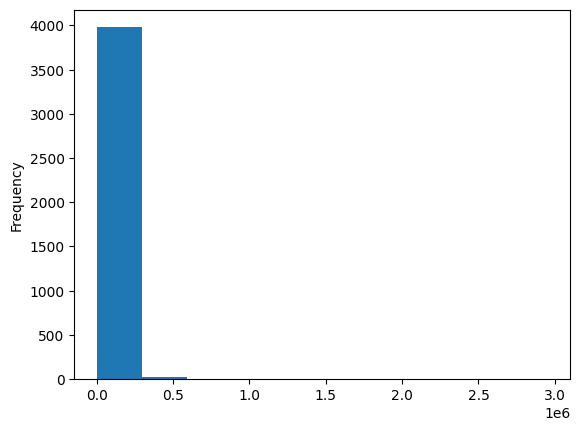

In [11]:
df['price'].plot(kind='hist')

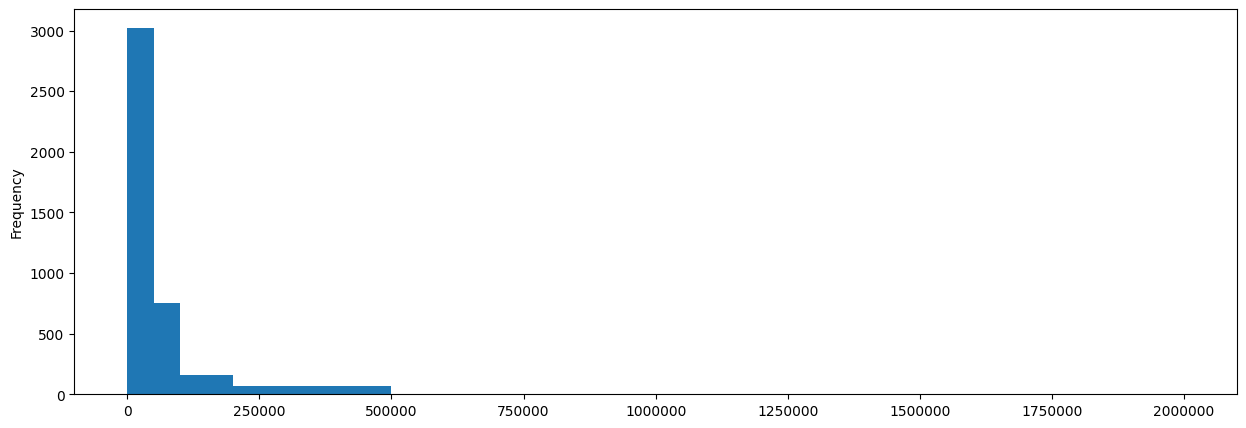

In [12]:
import matplotlib.pyplot as plt

df['price'].plot(kind='hist', bins=[0, 50000, 100000, 200000, 500000, 750000, 1000000, 2000000], figsize=(15, 5))
plt.ticklabel_format(style='plain', axis='x')

<Axes: ylabel='Frequency'>

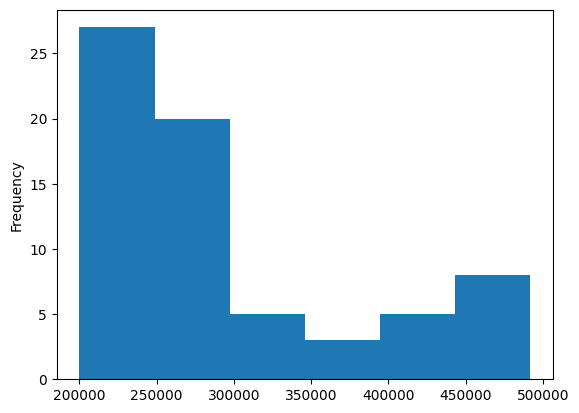

In [13]:
df[(df['price'] >= 200000) & (df['price'] <= 500000)]['price'].plot(kind='hist', bins=6)

In [14]:
df[df['price'] > 300000].describe().round(0).astype(int)

,model_year,milage,price
count,28,28,28
mean,2018,5346,643739
std,5,6393,581739
min,2005,115,314900
25%,2017,1254,389923
50%,2019,3852,459948
75%,2021,7136,599249
max,2023,32000,2954083


In [15]:
print('Porcentaje de coches con precio mayor que 300.000$ =',((df['price'] > 300000).mean() * 100).round(3))
print('Número de resgistos considerados "outliers" y que no deberían entrar en el cálculo =', (df['price'] > 300000).sum())

Porcentaje de coches con precio mayor que 300.000$ = 0.698
Número de resgistos considerados "outliers" y que no deberían entrar en el cálculo = 28


In [16]:
display(pd.qcut(df['price'], q=4).value_counts())

,count
price,
"(17200.0, 31000.0]",1007
"(1999.999, 17200.0]",1004
"(49990.0, 2954083.0]",1002
"(31000.0, 49990.0]",996


In [17]:
display(pd.qcut(df['price'], q=10, precision=0).value_counts(sort=False))

,count
price,
"(1999.0, 9950.0]",407
"(9950.0, 15000.0]",423
"(15000.0, 19786.0]",373
"(19786.0, 25930.0]",401
"(25930.0, 31000.0]",407
"(31000.0, 37900.0]",398
"(37900.0, 45000.0]",409
"(45000.0, 55540.0]",389
"(55540.0, 79999.0]",403


In [18]:
etiquetas = ['2.000 - 17.200 $', '17.200 - 31.000 $', '31.000 - 49.990 $', '49.990 - 300.00 $', 'más de 300.000']
display(pd.qcut(df['price'], q=5, labels=etiquetas).value_counts(sort=False))

,count
price,
2.000 - 17.200 $,830
17.200 - 31.000 $,774
31.000 - 49.990 $,805
49.990 - 300.00 $,798
más de 300.000,802


In [19]:
cortes = [0, 2000, 10000, 50000, 100000, 150000, 200000, 300000, float('inf')]
etiquetas = ['0 - 2k', '2k - 10k', '10k - 50k', '50k - 100k', '100k - 150k', '150k - 200k', '200k - 300k', 'Más de 300k']

display(pd.cut(df['price'], bins=cortes, labels=etiquetas).value_counts(sort=False))

,count
price,
0 - 2k,1
2k - 10k,444
10k - 50k,2600
50k - 100k,730
100k - 150k,116
150k - 200k,43
200k - 300k,47
Más de 300k,28


In [20]:
cortes = [0, 2000, 10000, 50000, 100000, 150000, 200000, 300000, float('inf')]
etiquetas = ['0 - 2k', '2k - 10k', '10k - 50k', '50k - 100k', '100k - 150k', '150k - 200k', '200k - 300k', 'Más de 300k']

tramos = pd.cut(df['price'], bins=cortes, labels=etiquetas)

tabla_precios = pd.DataFrame({
    'Coches': tramos.value_counts(sort=False),
    'Porcentaje (%)': (tramos.value_counts(sort=False, normalize=True) * 100).round(2)
})

display(tabla_precios)

,Coches,Porcentaje (%)
price,,
0 - 2k,1,0.02
2k - 10k,444,11.08
10k - 50k,2600,64.85
50k - 100k,730,18.21
100k - 150k,116,2.89
150k - 200k,43,1.07
200k - 300k,47,1.17
Más de 300k,28,0.70


## **Análisis y Limpieza de la Variable Objetivo (`price`)**

### 1. Diagnóstico de la Distribución
Al analizar los **4.009 registros** del dataset **`used_cars.csv`**, observamos que la variable `price` presenta una **fuerte asimetría positiva** (sesgada hacia la derecha):

<br>

* Mientras que la **mediana** se sitúa en torno a los **31.000\$**, los valores extremos alcanzan casi los **3.000.000$**
* Estos vehículos de altísima gama (*outliers*) distorsionan la escala general y perjudican el rendimiento de futuros modelos de regresión.

<br>

### 2. Segmentación por Tramos de Precio y Decisión de Corte
Para identificar dónde se concentra realmente el mercado y dónde empieza el ruido estadístico, segmentamos `price` mediante `pd.cut()` incluyendo el peso acumulado y la decisión tomada sobre cada tramo:

| Rango de Precio (\$) | Nº de Vehículos | Porcentaje (%) | % Acumulado | Decisión en el Modelo |
| :--- | :---: | :---: | :---: | :---: |
| **0 - 2.000 \$** | 1 | 0,02 % | 0,02 % | ❌ Descartado (*outlier* inferior) |
| **2.000 - 10.000 \$** | 444 | 11,08 % | 11,10 % | ✅ Conservado |
| **10.000 - 50.000 \$** | 2.600 | 64,85 % | 75,95 % | ✅ Conservado (grueso del mercado) |
| **50.000 - 100.000 \$** | 730 | 18,21 % | 94,16 % | ✅ Conservado |
| **100.000 - 150.000 \$** | 116 | 2,89 % | **97,05 %** | ✅ **Conservado (punto de corte)** |
| **150.000 - 200.000 \$** | 43 | 1,07 % | 98,12 % | ❌ Descartado (baja densidad) |
| **200.000 - 300.000 \$** | 47 | 1,17 % | 99,29 % | ❌ Descartado (baja densidad) |
| **Más de 300.000 \$** | 28 | 0,70 % | 100,00 % | ❌ Descartado (*outliers* extremos) |

<br>

**¿Por qué fijar el límite superior exactamente en 150.000 \$?**
* **El "punto dulce" de representatividad:** Hasta los **150.000 \$** retenemos **3.890 vehículos (97,03 % del dataset)**, asegurando que todos los segmentos incluidos tengan suficiente volumen de datos para entrenar el modelo con fiabilidad.
* **Caída drástica de densidad:** A partir de **150.000 \$**, cada tramo cae a apenas un **1 %** de la muestra (sumando solo 118 coches dispersos hasta casi los 3.000.000 \$). Mantener esa cola introduciría un sesgo enorme en el error de predicción a cambio de menos del 3 % de los registros.

<br>

### 3. Decisión de Filtrado y Justificación
Con el objetivo de modelar el mercado real de vehículos usados sin que los valores atípicos sesguen las predicciones, se establece el rango de análisis entre **2.000\$ y 150.000\$**:



* **Registros conservados:** **3.890 vehículos** (**97,03 %** del dataset original)
* **Registros descartados:** **119 vehículos** (**2,97 %** del total): 1 registro por debajo de 2.000\$ (posible error o vehículo siniestrado) y 118 vehículos de lujo por encima de 150.000$.

<br>

***Esta depuración elimina la cola extrema de precios sacrificando menos del 3 % de la muestra, garantizando una base sólida y representativa para las siguientes fases del análisis.***